# Сравнение карт и показателей

Часто нужно не просто показать показатель на карте, а сравнить: два года, два показателя или два региона. Чтобы такое сравнение было корректным, карты нужно оформлять по единым правилам.

В этом разделе мы:

- построим карты за два года с **единой легендой**;
- построим карты изменений и выберем для них палитру;
- проверим, связаны ли между собой два показателя;
- сохраним карту в файл для презентации.

## 0. Импорт библиотек и подготовка данных

### 0.1 Импорт библиотек

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mapclassify as mc
from matplotlib.colors import TwoSlopeNorm

import warnings
warnings.filterwarnings("ignore", message="Numba not installed")  # скрываем техническое предупреждение mapclassify

### 0.2 Подготовка данных

Прочитаем данные по Калужской области, подготовленные и сохранённые в разделе [Подготовка данных БДМО](mapping_2.ipynb). Если вы его ещё не выполнили, сначала выполните его.

In [2]:
muni_stat = gpd.read_file("../data/muni_stat.gpkg")

muni_stat[["name", "birth_rate_2016", "birth_rate_2020"]].head()

,name,birth_rate_2016,birth_rate_2020
0,Хвастовичский муниципальный район,13.503160,8.099095
1,Юхновский муниципальный район,10.173764,6.599713
2,город Обнинск,13.703305,9.087115
3,Бабынинский муниципальный район,12.668377,9.183841
4,Барятинский муниципальный район,7.927333,6.648936


## 1. Карты за два года

### 1.1. Независимые легенды

Построим карты коэффициента рождаемости за 2016 и 2020 годы. Для каждой карты классы рассчитываются отдельно:

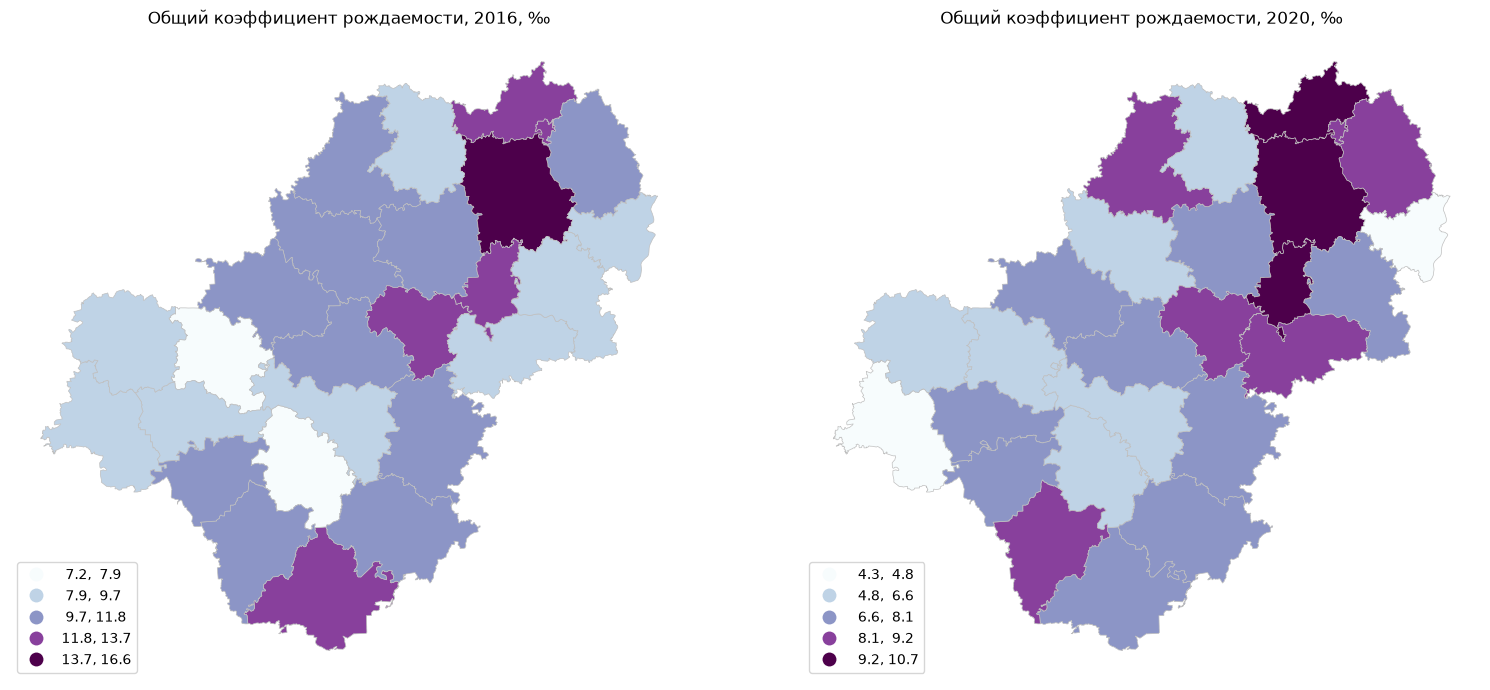

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, year in zip(axes, [2016, 2020]):
    muni_stat.plot(
        column=f"birth_rate_{year}",
        cmap="BuPu",
        scheme="FisherJenks",
        k=5,
        linewidth=0.5,
        edgecolor="0.75",
        legend=True,
        legend_kwds={"loc": "lower left", "fmt": "{:.1f}"},
        ax=ax
    )
    ax.set_title(f"Общий коэффициент рождаемости, {year}, ‰")
    ax.axis("off")

plt.tight_layout()
plt.show()

Карты выглядят похоже, и может показаться, что за четыре года мало что изменилось. Но посмотрите на легенды: в 2016 году к самому тёмному классу относятся значения выше 13,7‰, а в 2020 году максимум — 10,7‰. Один и тот же цвет на двух картах означает разные значения, поэтому сравнивать такие карты **нельзя**.

### 1.2. Единая легенда

Чтобы карты можно было сравнивать, рассчитаем **общие границы классов** по значениям за оба года сразу и используем их для обеих карт. Параметр `lowest` задаёт нижнюю границу первого класса — минимум по обоим годам:

In [4]:
all_values = pd.concat([
    muni_stat["birth_rate_2016"],
    muni_stat["birth_rate_2020"],
])

common_bins = mc.FisherJenks(all_values, k=5).bins

common_bins

array([ 6.64893617,  8.25382402,  9.65877603, 11.79835538, 16.58701712])

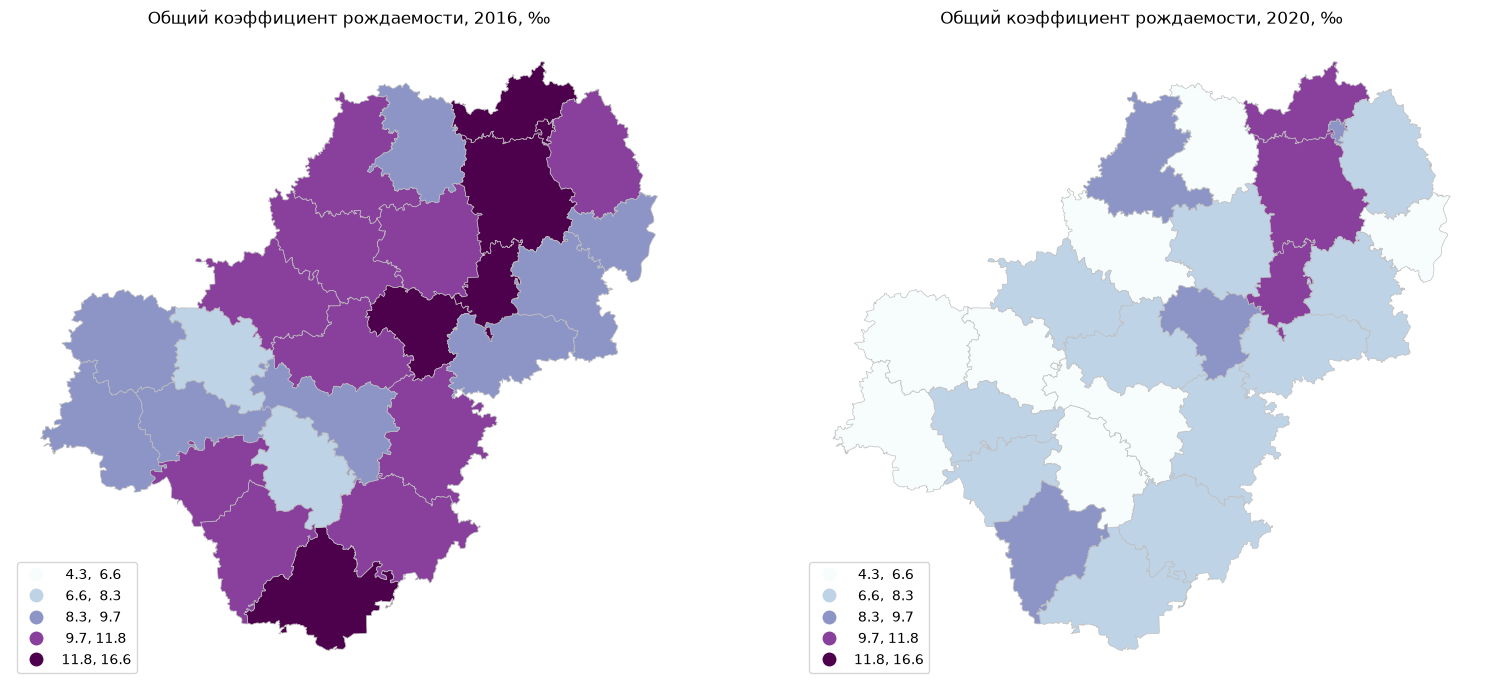

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, year in zip(axes, [2016, 2020]):
    muni_stat.plot(
        column=f"birth_rate_{year}",
        cmap="BuPu",
        scheme="UserDefined",
        classification_kwds={"bins": common_bins, "lowest": all_values.min()},
        linewidth=0.5,
        edgecolor="0.75",
        legend=True,
        legend_kwds={"loc": "lower left", "fmt": "{:.1f}"},
        ax=ax
    )
    ax.set_title(f"Общий коэффициент рождаемости, {year}, ‰")
    ax.axis("off")

plt.tight_layout()
plt.show()

Теперь один и тот же цвет на обеих картах означает один и тот же интервал значений, и сразу видно, что рождаемость за четыре года заметно снизилась по всей области.

## 2. Карты изменений

Две карты рядом показывают состояние в каждом году, но изменения приходится искать глазами. Нагляднее построить **карту изменений** — разницу между значениями за два года. Какую палитру для неё выбрать, зависит от того, какие значения получились.

### 2.1. Изменение рождаемости

In [6]:
muni_stat["birth_rate_change"] = muni_stat["birth_rate_2020"] - muni_stat["birth_rate_2016"]

muni_stat["birth_rate_change"].describe()

count    26.000000
mean     -3.072202
std       1.315729
min      -5.843973
25%      -3.630872
50%      -2.997187
75%      -2.548787
max      -0.440558
Name: birth_rate_change, dtype: float64

Рождаемость снизилась **во всех** муниципалитетах: даже наибольшее значение отрицательное. Значений по обе стороны от нуля нет, поэтому расходящаяся палитра здесь не нужна: на ней была бы только одна половина шкалы. Покажем величину снижения **последовательной** палитрой, в которой самый тёмный цвет соответствует самому сильному снижению (`Reds_r` — перевёрнутая палитра `Reds`):

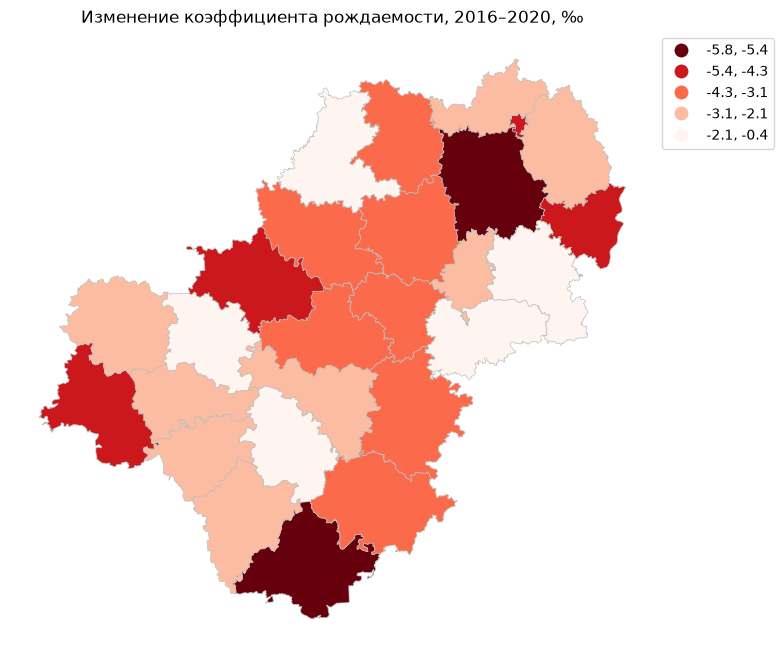

In [7]:
ax = muni_stat.plot(
    column="birth_rate_change",
    cmap="Reds_r",
    scheme="FisherJenks",
    k=5,
    linewidth=0.5,
    edgecolor="0.75",
    legend=True,
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1, 1), "fmt": "{:.1f}"},
    figsize=(9, 8)
)

ax.set_title("Изменение коэффициента рождаемости, 2016–2020, ‰")
ax.axis("off")

plt.show()

### 2.2. Изменение численности населения

Рассчитаем, на сколько процентов изменилась численность населения:

In [8]:
muni_stat["pop_change_pct"] = (muni_stat["pop_2020"] / muni_stat["pop_2016"] - 1) * 100

muni_stat["pop_change_pct"].describe()

count    26.000000
mean     -0.804683
std       4.093895
min     -11.598962
25%      -3.016556
50%      -1.871851
75%       1.747970
max       6.951724
Name: pop_change_pct, dtype: float64

Здесь есть и рост, и убыль, а у изменения появляется осмысленный центр — ноль. Поэтому используем **расходящуюся** палитру (см. раздел [Картограммы и методы классификации](mapping_1.ipynb)). Чтобы её центральный (белый) цвет соответствовал нулю, передадим в `plot()` нормализацию `TwoSlopeNorm` с центром `vcenter=0`:

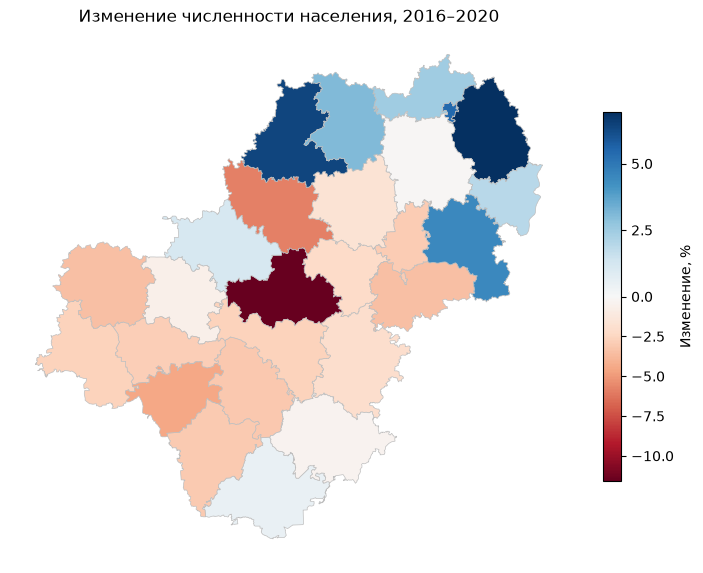

In [9]:
change = muni_stat["pop_change_pct"]
norm = TwoSlopeNorm(vmin=change.min(), vcenter=0, vmax=change.max())

ax = muni_stat.plot(
    column="pop_change_pct",
    cmap="RdBu",
    norm=norm,
    linewidth=0.5,
    edgecolor="0.75",
    legend=True,
    legend_kwds={"label": "Изменение, %", "shrink": 0.6},
    figsize=(9, 8)
)

ax.set_title("Изменение численности населения, 2016–2020")
ax.axis("off")

plt.show()

Население растёт на севере области, ближе к Москве: в Обнинске, Жуковском, Боровском, Медынском и Износковском районах. На большей части области население убывает, сильнее всего в Мещовском районе (−11,6 %). Обратите внимание, что сама Калуга тоже теряет население (−2,9 %).

## 3. Связь между показателями

Связаны ли между собой два показателя? Например, растёт ли население там, где выше рождаемость?

### 3.1. Диаграмма рассеяния

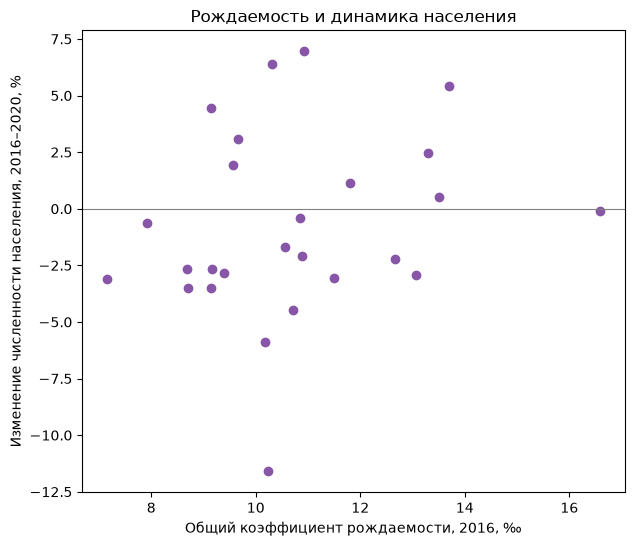

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(muni_stat["birth_rate_2016"], muni_stat["pop_change_pct"], color="#8856a7")

ax.axhline(0, color="0.5", linewidth=0.8)
ax.set_xlabel("Общий коэффициент рождаемости, 2016, ‰")
ax.set_ylabel("Изменение численности населения, 2016–2020, %")
ax.set_title("Рождаемость и динамика населения")

plt.show()

### 3.2. Коэффициент корреляции

Оценим силу связи с помощью коэффициентов корреляции:

- **Пирсона** — для линейной связи;
- **Спирмена** — для монотонной связи; он менее чувствителен к выбросам.

Значения близки к 1 при сильной прямой связи, к −1 — при сильной обратной, к 0 — при отсутствии связи.

In [11]:
pair = muni_stat[["birth_rate_2016", "pop_change_pct"]].dropna()

print(f"Пирсон:  {pair.corr(method='pearson').iloc[0, 1]:.2f}")
print(f"Спирмен: {pair.corr(method='spearman').iloc[0, 1]:.2f}")

Пирсон:  0.21
Спирмен: 0.34


Связь слабая. При интерпретации помните:

- **корреляция не означает причинно-следственную связь**: оба показателя могут зависеть от третьего фактора. Например, рост населения у границы с Московской областью связан прежде всего с миграцией, а не с рождаемостью;
- при небольшом числе объектов (у нас их 26) коэффициент неустойчив: одна-две точки могут заметно его изменить. Всегда смотрите на диаграмму рассеяния, а не только на коэффициент.

## 4. Сохранение карты

Для презентации или отчёта карту нужно сохранить в файл. Для этого используется метод `savefig()`:

- `dpi` — разрешение (для презентаций достаточно 200–300);
- `bbox_inches="tight"` — обрезать лишние поля, чтобы легенда и заголовок не обрезались.

Сохраним карту изменения численности населения:

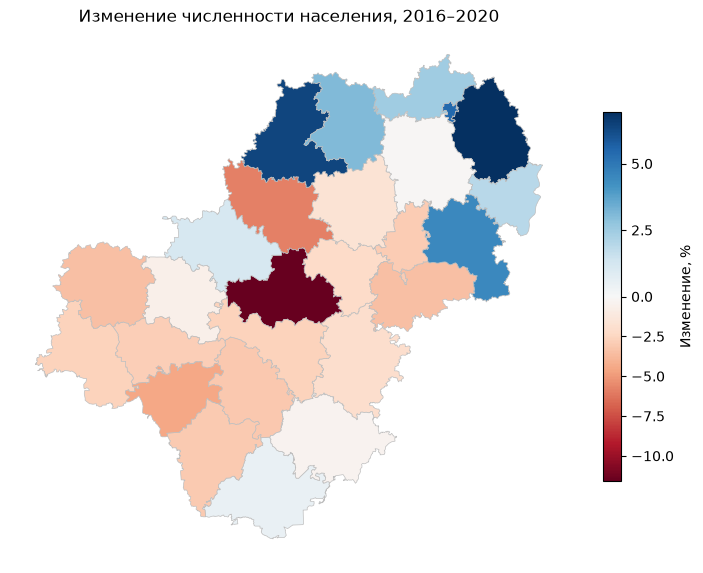

In [12]:
ax = muni_stat.plot(
    column="pop_change_pct",
    cmap="RdBu",
    norm=norm,
    linewidth=0.5,
    edgecolor="0.75",
    legend=True,
    legend_kwds={"label": "Изменение, %", "shrink": 0.6},
    figsize=(9, 8)
)
ax.set_title("Изменение численности населения, 2016–2020")
ax.axis("off")

plt.savefig("pop_change.png", dpi=300, bbox_inches="tight")
plt.show()

> Вызывайте `savefig()` **до** `plt.show()`: после показа рисунок очищается, и в файл сохранится пустое изображение.

## Итог

В этом разделе мы научились корректно сравнивать карты:

1. Карты за разные годы можно сравнивать, только если у них **единая легенда** — общие границы классов, рассчитанные по всем значениям сразу. С независимыми легендами снижение рождаемости по всей области на картах было не видно.
2. Палитру для **карты изменений** выбирают по данным. Если все значения одного знака, подходит последовательная палитра. Если есть и рост, и снижение, нужна расходящаяся палитра, центрированная на нуле.
3. Связь между показателями можно проверить с помощью **диаграммы рассеяния** и **коэффициентов корреляции**, помня, что корреляция не означает причинности, а при малом числе объектов коэффициент неустойчив.
4. Для презентации карту сохраняют в файл с помощью `savefig()`.